# **-- Regression --** #

# import all required libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

# Load Dataset

In [2]:
df = pd.read_csv(r"D:\DATA SCIENCE\Machine Learning\Task\ecommerce_multitask_dataset.csv")

In [3]:
df.head()

,CustomerID,Age,AnnualIncome,SpendingScore,TotalPurchases,ChurnStatus,TotalSpent,ItemsBought
0,CUST_1000,56,125186,58,13,0,16247.405882,Charger
1,CUST_1001,69,54674,67,49,0,21973.364975,"T-Shirt,Shoes,Phone"
2,CUST_1002,46,55854,56,41,0,19399.861629,Smartwatch
3,CUST_1003,32,66271,40,17,0,12791.643911,"Smartwatch,Cover,Phone,Mouse"
4,CUST_1004,60,93688,98,9,0,21285.349780,"Cover,Keyboard,Charger,Phone"


# Plot

<Axes: xlabel='SpendingScore', ylabel='TotalPurchases'>

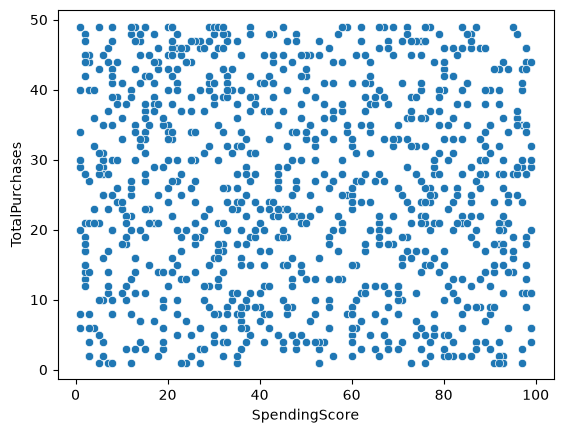

In [4]:
sns.scatterplot(x= "SpendingScore", y="TotalPurchases", data= df)

In [5]:
df.columns

Index(['CustomerID', 'Age', 'AnnualIncome', 'SpendingScore', 'TotalPurchases',
       'ChurnStatus', 'TotalSpent', 'ItemsBought'],
      dtype='object')

# Polynomial features

In [6]:
Poly = PolynomialFeatures(degree=2)

In [7]:
X =df[['Age', 'AnnualIncome','TotalPurchases', 'TotalSpent']]
Y = df["SpendingScore"]

In [8]:
X= Poly.fit_transform(X)
X

array([[1.00000000e+00, 5.60000000e+01, 1.25186000e+05, ...,
        1.69000000e+02, 2.11216276e+05, 2.63978198e+08],
       [1.00000000e+00, 6.90000000e+01, 5.46740000e+04, ...,
        2.40100000e+03, 1.07669488e+06, 4.82828768e+08],
       [1.00000000e+00, 4.60000000e+01, 5.58540000e+04, ...,
        1.68100000e+03, 7.95394327e+05, 3.76354631e+08],
       ...,
       [1.00000000e+00, 6.20000000e+01, 1.32863000e+05, ...,
        1.36900000e+03, 7.37556077e+05, 3.97362284e+08],
       [1.00000000e+00, 3.50000000e+01, 1.35005000e+05, ...,
        1.76400000e+03, 7.51096829e+05, 3.19810910e+08],
       [1.00000000e+00, 5.50000000e+01, 2.23960000e+04, ...,
        1.36900000e+03, 5.45755698e+05, 2.17567043e+08]], shape=(1000, 15))

# Split Training And Testing Data

In [9]:
X_train, X_test,Y_train, Y_test= train_test_split(
    X,Y, test_size= 0.20, random_state= 42
)

# define model

In [10]:
model= LinearRegression()

# train model

In [11]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](15,)","[ 0., 0.,-0.,...,-0.,-0., 0.]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,21.29
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,7
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](15,)","[1.91e+11,1.43e+10,1.70e+09,...,6.39e+01,5.51e+01,0.00e+00]"


# model accuracy score

In [12]:
Y_pred= model.predict(X_test)

score= r2_score(Y_test,Y_pred)
score

0.9481225819509114

# **-- Classification --** #

In [13]:
df.columns

Index(['CustomerID', 'Age', 'AnnualIncome', 'SpendingScore', 'TotalPurchases',
       'ChurnStatus', 'TotalSpent', 'ItemsBought'],
      dtype='object')

# import required libraries

In [14]:
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier 
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# split Columns

In [15]:
X_class= df[['Age', 'AnnualIncome','TotalPurchases', 'TotalSpent','SpendingScore']]
Y_class= df['ChurnStatus']

# Split training ad testing data

In [16]:
X_train_Classification , X_test_Classification , Y_train_Classification , Y_test_Classification = train_test_split(
    X_class,Y_class, test_size = 0.2, random_state = 42
)

# define model

In [17]:
Classification_Model= Pipeline([
    ("Scaler",StandardScaler()),
    ("Classification_Model",RandomForestClassifier(n_estimators=19))
])

# 

# train model

In [18]:
Classification_Model.fit(X_train_Classification,Y_train_Classification)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Scaler', ...), ('Classification_Model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['Age','AnnualIncome','TotalPurchases','TotalSpent','SpendingScore']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


# model accuracy score

In [19]:
Y_pred_classification= Classification_Model.predict(X_test_Classification)
Classification_score= accuracy_score(Y_test_Classification,Y_pred_classification)
Classification_score

1.0

# **-- Clustering --** #

# import required libraries

In [20]:
import matplotlib.pyplot as plt 

import seaborn as sns 

from sklearn.cluster import KMeans

In [21]:
df.columns

Index(['CustomerID', 'Age', 'AnnualIncome', 'SpendingScore', 'TotalPurchases',
       'ChurnStatus', 'TotalSpent', 'ItemsBought'],
      dtype='object')

# define input functions

In [22]:
X_cluster= df[['Age', 'AnnualIncome', 'SpendingScore', 'TotalPurchases', 'TotalSpent']]

# define model

In [23]:
model_cluster= KMeans(
    n_clusters=3,
    n_init=11,
    random_state=42
)

# fit model

In [24]:
model_cluster.fit(X_cluster)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",11
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 5)","[[ 43

# make clusters

In [25]:
df['Cluster']=model_cluster.predict(X_cluster)

In [26]:
df.head()

,CustomerID,Age,AnnualIncome,SpendingScore,TotalPurchases,ChurnStatus,TotalSpent,ItemsBought,Cluster
0,CUST_1000,56,125186,58,13,0,16247.405882,Charger,2
1,CUST_1001,69,54674,67,49,0,21973.364975,"T-Shirt,Shoes,Phone",1
2,CUST_1002,46,55854,56,41,0,19399.861629,Smartwatch,1
3,CUST_1003,32,66271,40,17,0,12791.643911,"Smartwatch,Cover,Phone,Mouse",0
4,CUST_1004,60,93688,98,9,0,21285.349780,"Cover,Keyboard,Charger,Phone",0


In [41]:
df.to_csv("Updated_Ecommerce_data_with_clusters.csv",index=False)

# cluster visualization

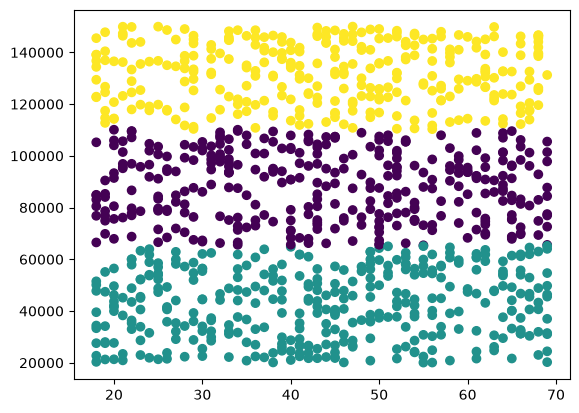

In [27]:
plt.scatter(df["Age"],df["AnnualIncome"],c=df["Cluster"])
plt.show()

# **-- Association --**

# import required libraries

In [28]:
from sklearn.metrics import classification_report
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori , association_rules 

In [29]:
df.head()

,CustomerID,Age,AnnualIncome,SpendingScore,TotalPurchases,ChurnStatus,TotalSpent,ItemsBought,Cluster
0,CUST_1000,56,125186,58,13,0,16247.405882,Charger,2
1,CUST_1001,69,54674,67,49,0,21973.364975,"T-Shirt,Shoes,Phone",1
2,CUST_1002,46,55854,56,41,0,19399.861629,Smartwatch,1
3,CUST_1003,32,66271,40,17,0,12791.643911,"Smartwatch,Cover,Phone,Mouse",0
4,CUST_1004,60,93688,98,9,0,21285.349780,"Cover,Keyboard,Charger,Phone",0


# make item list

In [30]:
data_new = (
    df["ItemsBought"]
    .fillna("")
    .apply(lambda x: [item.strip() for item in x.split(",") if item.strip()])
    .tolist()
)


# TransactionEncoder

In [31]:
trans = TransactionEncoder()

In [32]:
data_new_1= trans.fit_transform(data_new)

In [33]:
data_new_1

array([[ True, False, False, ..., False, False, False],
       [False, False, False, ...,  True, False,  True],
       [False, False, False, ..., False,  True, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False,  True, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]], shape=(1000, 10))

In [34]:
new_data_2 = pd.DataFrame(data_new_1,columns=trans.columns_)

In [35]:
new_data_2

,Charger,Cover,Headphones,Keyboard,Laptop,Mouse,Phone,Shoes,Smartwatch,T-Shirt
0,True,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,True,True,False,True
2,False,False,False,False,False,False,False,False,True,False
3,False,True,False,False,False,True,True,False,True,False
4,True,True,False,True,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...
995,False,False,True,False,False,False,False,False,False,False
996,False,False,False,False,False,False,False,False,False,True
997,False,False,False,False,True,False,True,False,False,False
998,False,True,False,True,False,False,True,False,False,False


# Apply apriori 

In [36]:
Data_pairs = apriori(new_data_2,min_support=0.04,use_colnames=True)

In [37]:
Data_pairs

,support,itemsets
0,0.241,(Charger)
1,0.264,(Cover)
2,0.251,(Headphones)
3,0.266,(Keyboard)
4,0.241,(Laptop)
5,0.239,(Mouse)
6,0.273,(Phone)
7,0.257,(Shoes)
8,0.250,(Smartwatch)
9,0.250,(T-Shirt)


# Association Rule

In [38]:
Rule = association_rules(Data_pairs,metric="confidence",min_threshold=0.1)
Rule

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(Charger),(Cover),0.241,0.264,0.059,0.244813,0.927323,1.0,-0.004624,0.974593,-0.093594,0.132287,-0.026069,0.234149
1,(Cover),(Charger),0.264,0.241,0.059,0.223485,0.927323,1.0,-0.004624,0.977444,-0.096237,0.132287,-0.023077,0.234149
2,(Charger),(Headphones),0.241,0.251,0.050,0.207469,0.826569,1.0,-0.010491,0.945073,-0.216573,0.113122,-0.058119,0.203336
3,(Headphones),(Charger),0.251,0.241,0.050,0.199203,0.826569,1.0,-0.010491,0.947806,-0.218831,0.113122,-0.055068,0.203336
4,(Charger),(Keyboard),0.241,0.266,0.065,0.269710,1.013946,1.0,0.000894,1.005080,0.018121,0.147059,0.005054,0.257035
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,(Shoes),(Smartwatch),0.257,0.250,0.062,0.241245,0.964981,1.0,-0.002250,0.988462,-0.046568,0.139326,-0.011673,0.244623
86,(Shoes),(T-Shirt),0.257,0.250,0.052,0.202335,0.809339,1.0,-0.012250,0.940244,-0.240734,0.114286,-0.063554,0.205167
87,(T-Shirt),(Shoes),0.250,0.257,0.052,0.208000,0.809339,1.0,-0.012250,0.938131,-0.239024,0.114286,-0.065949,0.205167
88,(Smartwatch),(T-Shirt),0.250,0.250,0.060,0.240000,0.960000,1.0,-0.002500,0.986842,-0.052632,0.136364,-0.013333,0.240000


In [39]:
DF = Rule[['antecedents', 'consequents','support','confidence', 'lift']]

In [40]:
DF

,antecedents,consequents,support,confidence,lift
0,(Charger),(Cover),0.059,0.244813,0.927323
1,(Cover),(Charger),0.059,0.223485,0.927323
2,(Charger),(Headphones),0.050,0.207469,0.826569
3,(Headphones),(Charger),0.050,0.199203,0.826569
4,(Charger),(Keyboard),0.065,0.269710,1.013946
...,...,...,...,...,...
85,(Shoes),(Smartwatch),0.062,0.241245,0.964981
86,(Shoes),(T-Shirt),0.052,0.202335,0.809339
87,(T-Shirt),(Shoes),0.052,0.208000,0.809339
88,(Smartwatch),(T-Shirt),0.060,0.240000,0.960000


In [42]:
DF.to_csv("Association_report.csv",index=False)